In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

# Load processed Titanic datasets
data_path = Path("/kaggle/input")

train = pd.read_csv(next(data_path.rglob("titanic_train_processed.csv")))
test = pd.read_csv(next(data_path.rglob("titanic_test_processed.csv")))

X_train = train.drop(columns="Survived").values
y_train = train["Survived"].values

X_test = test.drop(columns="Survived").values
y_test = test["Survived"].values

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (712, 10) (712,)
Testing: (179, 10) (179,)


In [2]:

# Logistic Regression using Adam Optimizer

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

X = np.c_[np.ones(len(X_train)), X_train]

weights = np.zeros(X.shape[1])
m = np.zeros_like(weights)
v = np.zeros_like(weights)

lr = 0.01
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
epochs = 2000
loss_history = []

for epoch in range(1, epochs + 1):
    predictions = sigmoid(X @ weights)
    gradient = X.T @ (predictions - y_train) / len(y_train)

    # Adam update
    m = beta1 * m + (1 - beta1) * gradient
    v = beta2 * v + (1 - beta2) * gradient**2

    m_hat = m / (1 - beta1**epoch)
    v_hat = v / (1 - beta2**epoch)

    weights -= lr * m_hat / (np.sqrt(v_hat) + epsilon)

    # Binary Cross-Entropy Loss
    p = np.clip(sigmoid(X @ weights), 1e-10, 1 - 1e-10)
    loss = -np.mean(y_train * np.log(p) +
                    (1 - y_train) * np.log(1 - p))
    loss_history.append(loss)

print("Adam Training Completed!")
print("Final Training Loss:", loss_history[-1])
print("Learned Weights:", weights)


Adam Training Completed!
Final Training Loss: 0.436109994997053
Learned Weights: [-0.66227829 -0.95199863 -0.5186134  -0.26881351 -0.07058704  0.0917472
  0.64377688 -0.64377688  0.07987255  0.13903283 -0.08420648]


Accuracy : 0.8100558659217877
Precision: 0.7966101694915254
Recall   : 0.6811594202898551
F1 Score : 0.734375
Test Loss: 0.46361711901561276


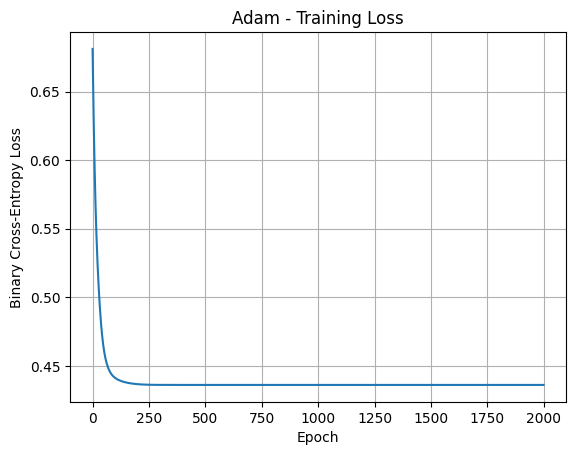

In [3]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Test predictions
X_test_bias = np.c_[np.ones(len(X_test)), X_test]
probs = sigmoid(X_test_bias @ weights)
y_pred = (probs >= 0.5).astype(int)

# Binary Cross-Entropy Loss
p = np.clip(probs, 1e-10, 1 - 1e-10)
test_loss = -np.mean(y_test * np.log(p) +
                     (1 - y_test) * np.log(1 - p))

# Evaluation metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
print("Test Loss:", test_loss)

# Training Loss Curve
plt.plot(loss_history)
plt.title("Adam - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()
